In [1]:
import numpy as np
import scipy
import scipy.linalg
import random
import math
import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import qr, svd
from tqdm import tqdm
from mpl_toolkits.mplot3d import Axes3D
from scipy.linalg import expm as exp
    

In [2]:
def H(num):
    H = np.diag(np.ones(num-1),-1)+np.diag(np.ones(num-1),1)
    H[num-1,0]=H[0,num-1]=1

    return H

In [38]:
def qr_householder(A):
    m, n = A.shape
    R = A.copy()
    Q = np.identity(m)
    for i in range(0, n - 1):
        alpha = np.linalg.norm(R[i:, i], 2)
        avec = np.zeros_like(R[i:, [i]])
        avec[0] = alpha
        u = R[i:, [i]] - avec
        v = u / np.linalg.norm(u, 2)
        Qn = np.identity(m - i) - (2 * np.dot(v, v.T))
        Qn = np.block([[np.eye(i), np.zeros((i, m - i))], 
                       [np.zeros((m - i, i)), Qn]])
        R = np.dot(Qn, R)
        Q = np.dot(Q, Qn.T)
    return Q, R

In [4]:
def initial(num):
    U = np.zeros((num,num//2),dtype=np.complex_)
    for i in range(num//2):
        U[2*i,i]=1+0*1j
    return U, qr(U)[0]

def normalize(U):
    L, N = U.shape
    V=np.empty((L,N),dtype=np.complex_)
    for j in range(N):
        V[:,j]=U[:,j]
        for k in range(j):
            V[:,j]=V[:,j]-np.vdot(U[:,j],V[:,k])*V[:,k]
        V[:,j]=V[:,j]/np.linalg.norm(V[:,j])
    return V 

In [5]:
def generate_gaussian_noise(num_points, num_channels, gamma, dt):
    std_dev = np.sqrt(gamma * dt)
    noise = np.random.normal(loc=0.0, scale=std_dev, size=(num_channels, num_points))
    return noise


In [6]:

def evolution(U_i,H,gamma,dt):
    D = np.dot(U_i,U_i.conjugate().T)
    nj= np.diag(D).real
    
    M=np.zeros((U_i.shape[0],U_i.shape[0]),dtype=np.complex_)
    for i in range(U_i.shape[0]):
        M[i,i]=random.gauss(mu=0, sigma=np.sqrt(gamma*dt))/dt+gamma*(2*nj[i]-1)/2

    h = H+1j*M
    U = np.dot(scipy.linalg.expm(-1j*h*dt),U_i)
    
    return U,normalize(U),nj[0],nj[1] #qr_householder(U)[0],


    


In [7]:
def evolutionx(U_i,H,gamma,dt):
    N = U_i@U_i.conj().T
    nj= np.diag(N).real
    Noise = np.diag(generate_gaussian_noise(U_i.shape[0], 1, gamma, dt)[0])
    M = np.zeros((U_i.shape[0],U_i.shape[0]), dtype=np.complex_)
    
    for i in range(U_i.shape[0]):
        M[i,i] =  Noise[i,i]+ gamma*(2*nj[i]-1)*dt

    U_tdt =  exp(M)@exp(-1j*H*dt)@U_i
    U_tnorm = normalize(U_tdt)
    
    return U_tdt,qr(U_tdt,mode= 'economic')[0], U_tnorm,nj[0],nj[1]


In [8]:
def correlation_expression(Q_t, Q_tp,U_t, U_tp, i, j):

    # Compute U(t)U^\dag(t) and U(t')U^\dag(t')
    D_t = np.dot(U_t,U_t.conj().T)
    D_tp = np.dot(U_tp, U_tp.conj().T)
    D_4 = np.dot(U_t,U_tp.conjugate().T)
    D_3 = np.dot(U_tp ,U_t.conjugate().T)
    D_5 = np.dot(Q_t,Q_tp.conj().T)
    
    # Compute the terms
    term1 = D_t[i, i]*D_tp[j, j] # [U(t)U^\dag(t)]_{ii} * [U(t')U^\dag(t')]_{jj}
    term2 = D_3[j, i]*D_4[i,j]  # |[U(t')U^\dag(t)]_{ji}|^2
    term3 = D_3[j,i]*D_5[i,j]
    



    # Final expression
    return term1- term2 + term3



In [51]:
num = 50  # System size
N = 10
gamma = 0
dt = 0.05
t_values = np.arange(0,N+dt,dt)  
i, j = 1, 2

t_prime = t_values[len(t_values)//2]
trajec = 10

correlation_avg = np.zeros((trajec,len(t_values)), dtype = np.complex128)

time_differences = t_values - t_prime 

U_0,Q_0 = initial(num)
H_matrix = H(num)





for t in tqdm(range(trajec)):
    
    U_evolved = [U_0]  
    Q_evolved = [Q_0]
    U_tprime = U_0.copy()
    Q_tprime = Q_0.copy()


    Q = Q_0.copy()



    for _ in range(len(t_values)):
        Q,_,_, _,_ = evolutionx(Q, H_matrix, gamma, dt)
        Q_evolved.append(Q)
        U_evolved.append(Q[:,:int(num/2)])



    U_t_prime = U_evolved[0]
    Q_t_prime = Q_evolved[0]
    for t_idx in range(len(t_values)):
        correlation_avg[t,t_idx] = correlation_expression(Q_evolved[t_idx],Q_t_prime, U_evolved[t_idx] ,U_t_prime, i, j)
        #correlation_avg2[t_idx] = correlation_expression(Q_evolved[t_idx],Q_t_prime,  U_evolved[t_idx] , U_t_prime,j,i) 
        


100%|██████████| 10/10 [00:11<00:00,  1.14s/it]


In [52]:
num = 50  # System size
N = 10
gamma = 0.5
dt = 0.05
t_values = np.arange(0,N+dt,dt)  
i, j = 1, 2

t_prime = t_values[len(t_values)//2]
trajec = 10

correlation_avgr = np.zeros((trajec,len(t_values)), dtype = np.complex128)

time_differences = t_values - t_prime 

U_0,Q_0 = initial(num)
H_matrix = H(num)





for t in tqdm(range(trajec)):
    
    U_evolved = [U_0]  
    Q_evolved = [Q_0]
    U_tprime = U_0.copy()
    Q_tprime = Q_0.copy()


    Q = Q_0.copy()



    for _ in range(len(t_values)):
        _,Q,_, _,_ = evolutionx(Q, H_matrix, gamma, dt)
        Q_evolved.append(Q)
        U_evolved.append(Q[:,:int(num/2)])



    U_t_prime = U_evolved[0]
    Q_t_prime = Q_evolved[0]
    for t_idx in range(len(t_values)):
        correlation_avgr[t,t_idx] = correlation_expression(Q_evolved[t_idx],Q_t_prime, U_evolved[t_idx] ,U_t_prime, i, j)
        #correlation_avg2[t_idx] = correlation_expression(Q_evolved[t_idx],Q_t_prime,  U_evolved[t_idx] , U_t_prime,j,i) 

100%|██████████| 10/10 [00:12<00:00,  1.29s/it]


c:\Users\aniru\anaconda3\Lib\site-packages\matplotlib\cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\aniru\anaconda3\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


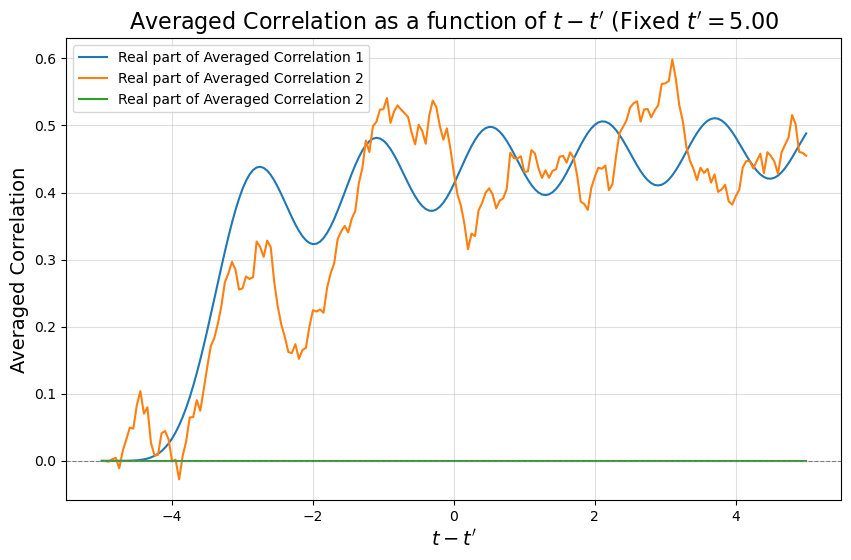

In [55]:
plt.figure(figsize=(10, 6))
plt.plot(time_differences, np.mean(correlation_avg,axis =0) , label="Real part of Averaged Correlation 1")
plt.plot(time_differences, np.mean(correlation_avgr,axis =0) , label="Real part of Averaged Correlation 2")
plt.plot(time_differences, np.mean(correlation_avgx,axis =0) , label="Real part of Averaged Correlation 2")
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.xlabel(r"$t - t'$", fontsize=14)
plt.ylabel("Averaged Correlation", fontsize=14)
plt.title(f"Averaged Correlation as a function of $t - t'$ (Fixed $t' = {t_prime:.2f}$", fontsize=16)
plt.legend()
plt.grid(alpha=0.4)
plt.show()

In [54]:
num = 50  # System size
N = 10
gamma = 0.5
dt = 0.05

t_values = np.arange(0,N+dt,dt)  
i, j = 1, 2

t_prime = t_values[len(t_values)//2]
trajec = 10


correlation_avgx = np.zeros((trajec,len(t_values)), dtype=np.complex128)

time_differences = t_values - t_prime 

U_0,Q_0 = initial(num)
H_matrix = H(num)





for t in tqdm(range(trajec)):
    
    U_evolved = [U_0]  
    Q_evolved = [Q_0]
    U_tprime = U_0.copy()
    Q_tprime = Q_0.copy()


    Q = Q_0.copy()



    for _ in range(len(t_values)):
        _,_,Q,_, _ = evolutionx(Q, H_matrix, gamma, dt)
        Q_evolved.append(Q)
        U_evolved.append(Q[:,:int(num/2)])



    U_t_prime = U_evolved[0]
    Q_t_prime = Q_evolved[0]
    for t_idx in range(len(t_values)):
        correlation_avgx[t,t_idx] = correlation_expression(Q_t_prime,Q_evolved[t_idx],   U_t_prime,U_evolved[t_idx] ,i,j) 

100%|██████████| 10/10 [00:11<00:00,  1.13s/it]


In [192]:
correlation_avgx

array([[ 0.        , -0.00272438, -0.00520543, ...,  0.29138999,
         0.29269177,  0.29400614],
       [ 0.        , -0.00272438, -0.00520543, ...,  0.29138999,
         0.29269177,  0.29400614]])

In [106]:
num = 50  # System size
N = 10
gamma = 0.02
dt = 0.01

t_values = np.arange(0,N+dt,dt)  
i, j = 1, 2

t_prime = t_values[len(t_values)//2]

correlation_avg = np.zeros(len(t_values))

correlation_avg2 = np.zeros(len(t_values))
time_differences = t_values - t_prime 



U_0,Q_0 = initial(num)
H_matrix = H(num)

U_evolved = [U_0]  
Q_evolved = [Q_0]
U_tprime = U_0.copy()
Q_tprime = Q_0.copy()


Q= Q_0.copy()



for _ in range(len(t_values)):
    _,_,Q,_,_ = evolutionx(Q, H_matrix, gamma, dt)
    Q_evolved.append(Q)
    U_evolved.append(Q[:,:int(num/2)])

# for _ in range(len(t_values)):
#     U,_,_,_, _ = evolutionx(U, H_matrix, gamma, dt)
#     U_evolved.append(U)
#     U_evolved.append(Q[:,:int(num/2)])



U_t_prime = U_evolved[51]
Q_t_prime = Q_evolved[51]



for t_idx in range(len(t_values)):
     correlation_avg[t_idx] = correlation_expression(Q_evolved[t_idx],Q_t_prime, U_evolved[t_idx] ,U_t_prime, i, j)
     #correlation_avg2[t_idx] = correlation_expression(Q_evolved[t_idx],Q_t_prime,  U_evolved[t_idx] , U_t_prime,j,i) 
     


C:\Users\aniru\AppData\Local\Temp\ipykernel_54492\863704110.py:49: ComplexWarning: Casting complex values to real discards the imaginary part
  correlation_avg[t_idx] = correlation_expression(Q_evolved[t_idx],Q_t_prime, U_evolved[t_idx] ,U_t_prime, i, j)


In [ ]:
dt=0.1
ti=0
tf=10
L=50
gamma = 0
H_mat = H(50)
t1=np.arange(ti,tf+dt,dt)
corr_u2=np.zeros((len(t1),len(t1)))
corr_u2u=np.zeros((len(t1),len(t1)))
N=int(L/2)

U0,Q0=initial(L)

Q1=Q0.copy()
Q2=Q0.copy()
for i in range(len(t1)):
    U1=Q1[:,:N]
    for j in range(len(t1)):
        if (j==0):
            Q2=Q0.copy()
        U2=Q2[:,:N]
        corr_u2[i,j]=correlation_expression(Q2,Q1,U2,U1,1,2)
        corr_u2u[i,j]=
        Q2,_,_,_=evolution(Q2,H_mat,gamma,dt)
    Q1,_,_,_=evolution(Q1,H_mat,gamma,dt)

C:\Users\aniru\AppData\Local\Temp\ipykernel_20108\2506446482.py:21: ComplexWarning: Casting complex values to real discards the imaginary part
  corr_u2[i,j]= correlation_expression(Q2,Q1,U2,U1,1,2)


KeyboardInterrupt: 

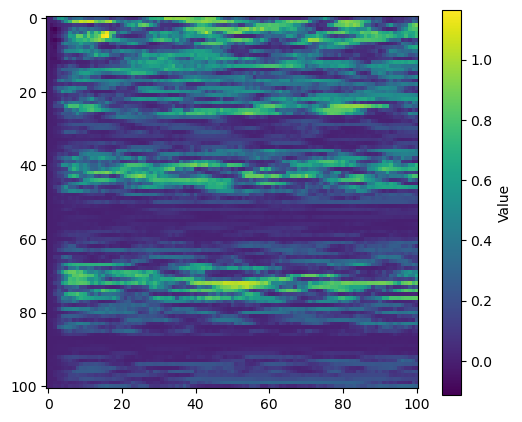

In [70]:
plt.figure(figsize=(6, 5))
plt.imshow(corr_u2, cmap='viridis', interpolation='nearest')

# Add color bar
plt.colorbar(label='Value')


In [21]:

dt=0.1
t1=np.arange(ti,tf+dt,dt)
corr_u=np.zeros((len(t1),len(t1)))
N=int(L/2)
h=np.zeros((L,L))
p=1
for i in range(L):
    for j in range(L):
        if (i==j-1 or i==j+1):
            h[i,j]=p
h[0,L-1]=p
h[L-1,0]=p
pos=1
U0=np.zeros((L,N))
for i in range(N):
    U0[2*i,i]=1
Q0,R0=qr(U0)
Q1=Q0.copy()
Q2=Q0.copy()
for i in range(len(t1)):
    U1=Q1[:,:N]
    for j in range(len(t1)):
        if (j==0):
            Q2=Q0.copy()
        U2=Q2[:,:N]
        corr_u[i,j]=np.dot(U1,np.transpose(np.conjugate(U1)))[pos,pos]*np.dot(U2,np.transpose(np.conjugate(U2)))[pos,pos] + np.dot(U2,np.transpose(np.conjugate(U1)))[pos,pos]*np.dot(Q1,np.transpose(np.conjugate(Q2)))[pos,pos] - np.dot(U2,np.transpose(np.conjugate(U1)))[pos,pos]*np.dot(U1,np.transpose(np.conjugate(U2)))[pos,pos]
        Q2=np.dot(exp(-1j*h*dt),Q2)
    Q1=np.dot(exp(-1j*h*dt),Q1)

C:\Users\aniru\AppData\Local\Temp\ipykernel_36728\995379634.py:26: ComplexWarning: Casting complex values to real discards the imaginary part
  corr_u[i,j]=np.dot(U1,np.transpose(np.conjugate(U1)))[pos,pos]*np.dot(U2,np.transpose(np.conjugate(U2)))[pos,pos] + np.dot(U2,np.transpose(np.conjugate(U1)))[pos,pos]*np.dot(Q1,np.transpose(np.conjugate(Q2)))[pos,pos] - np.dot(U2,np.transpose(np.conjugate(U1)))[pos,pos]*np.dot(U1,np.transpose(np.conjugate(U2)))[pos,pos]


In [216]:
corr_u2.shape

(101, 101)

In [15]:
from scipy.linalg import expm as exp

ti=0
tf=10
del_t=0.1
t=np.arange(ti,tf+del_t,del_t)
L=50
h=np.zeros((L,L))
p=1
for i in range(L):
    for j in range(L):
        if (i==j-1 or i==j+1):
            h[i,j]=p
h[0,L-1]=p
h[L-1,0]=p
pos=1
n=np.diag(np.array([(i+1)%2 for i in range(L)]))
I=np.identity(L)
corr_h=np.zeros((len(t),len(t)))
for i in range(len(t)):
    for j in range(len(t)):
        corr_h[i,j]=np.dot(exp(-1j*h*t[j]),np.dot(n,exp(1j*h*t[i])))[pos,pos]*np.dot(exp(-1j*h*t[i]),np.dot((I-n),exp(1j*h*t[j])))[pos,pos]+np.dot(exp(-1j*h*t[i]),np.dot(n,exp(1j*h*t[i])))[pos,pos]*np.dot(exp(-1j*h*t[j]),np.dot(n,exp(1j*h*t[j])))[pos,pos]


C:\Users\aniru\AppData\Local\Temp\ipykernel_36728\1558373086.py:22: ComplexWarning: Casting complex values to real discards the imaginary part
  corr_h[i,j]=np.dot(exp(-1j*h*t[j]),np.dot(n,exp(1j*h*t[i])))[pos,pos]*np.dot(exp(-1j*h*t[i]),np.dot((I-n),exp(1j*h*t[j])))[pos,pos]+np.dot(exp(-1j*h*t[i]),np.dot(n,exp(1j*h*t[i])))[pos,pos]*np.dot(exp(-1j*h*t[j]),np.dot(n,exp(1j*h*t[j])))[pos,pos]


In [145]:
num = 50  # System size
N = 10
gamma = 0
dt = 0.148

t_values = np.arange(0,N,dt)  # Array of times
i, j = 1, 2  # Indices for the correlation expression
trajectories = 1  # Number of trajectories for averaging

# Fix t'

t_prime = t_values[len(t_values)//2]

# Initialize arrays for storing averaged results
correlation_avg = np.zeros(len(t_values))
time_differences = t_values - t_prime  # Array of (t - t')


# Perform averaging over multiple trajectories
for trajectory in tqdm(range(trajectories)):
    # Initialize U(0)
    U_0,Q_0 = initial(num)
    H_matrix = H(num)

    # Precompute all evolved matrices for times t
    U_evolved = [U_0]  # Start with U(0)
    Q_evolved = [Q_0]
    U = U_0.copy()
    Q = Q_0.copy()
    # for _ in range(len(t_values) - 1):
    #     U, _, _ = evolution(U, H_matrix, gamma, dt)
    #     U_evolved.append(U)

    for _ in range(len(t_values) - 1):
        Q, _, _ = evolution(Q, H_matrix, gamma, dt)
        Q_evolved.append(Q)
        U_evolved.append(Q[:,:int(num/2)])
        
    # Extract U(t') for the fixed t'
    U_t_prime = U_evolved[t_prime]
    Q_t_prime = Q_evolved[t_prime]

    # Compute the correlation for all t and accumulate
    for t_idx, U_t in enumerate(U_evolved):
        correlation_avg[t_idx] += correlation_expression(Q_evolved[t_idx],Q_t_prime, U_t ,U_t_prime, i, j)

# Normalize by the number of trajectories
correlation_avg /= trajectories


# Plot correlation as a function of (t - t') with fixed t'


  0%|          | 0/1 [00:00<?, ?it/s]


TypeError: list indices must be integers or slices, not numpy.float64

c:\Users\aniru\anaconda3\Lib\site-packages\matplotlib\cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\aniru\anaconda3\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


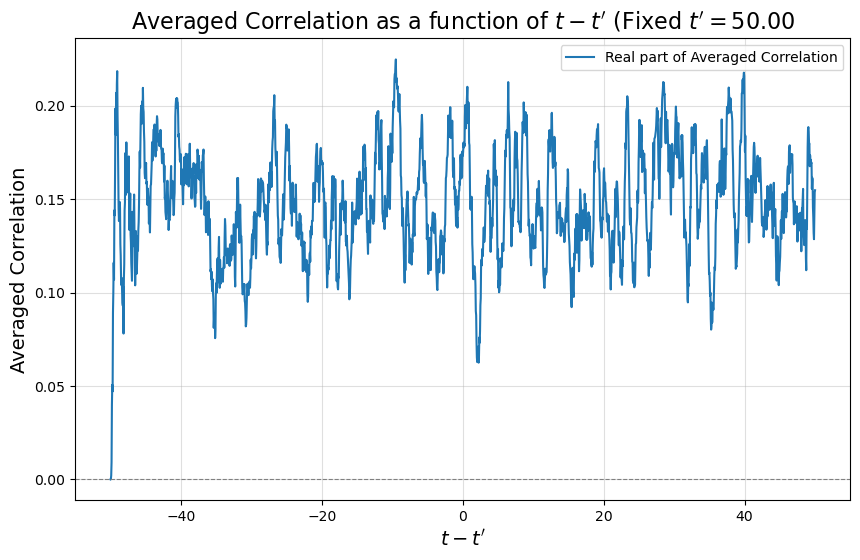

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(time_differences, np.mean(correlation_avg , axis = 0) , label="Real part of Averaged Correlation")
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.xlabel(r"$t - t'$", fontsize=14)
plt.ylabel("Averaged Correlation", fontsize=14)
plt.title(f"Averaged Correlation as a function of $t - t'$ (Fixed $t' = {t_prime:.2f}$", fontsize=16)
plt.legend()
plt.grid(alpha=0.4)
plt.show()

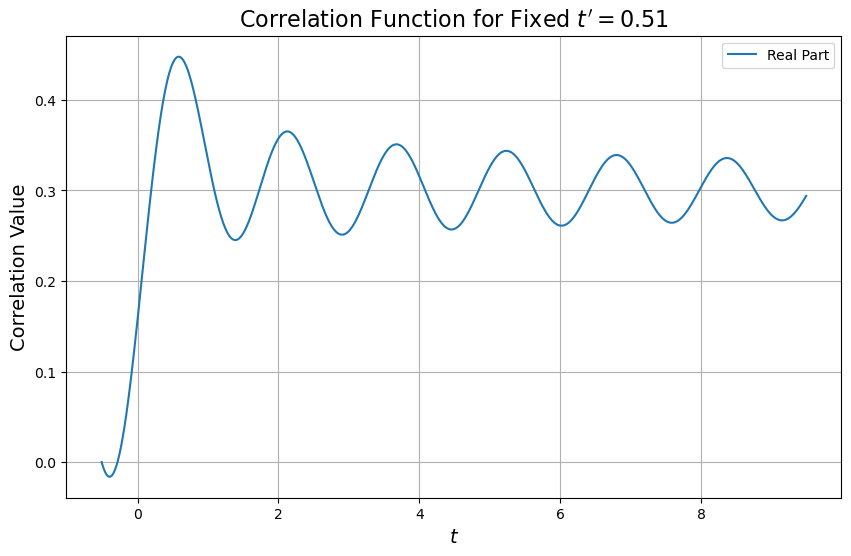

In [193]:
# Parameters
num = 50  # System size
N = 10
dt = 0.01
t_values = np.arange(0, N+dt,dt)  # Array of t values

t_primeh = t_values[51] #t_values[len(t_values)//2]

H_matrix = H(50)  # Define H


def hermitian_correlations(t, t_prime, H, U_0, i, j):
    
    # e^{-iHt}, e^{iHt}, e^{-iHt'}, e^{iHt'}
    exp_neg_iHt = exp(-1j * H * t)
    exp_neg_iHt_prime = exp(-1j * H * t_prime)
    exp_iHt = exp(1j * H * t)
    exp_iHt_prime = exp(1j * H * t_prime)
    
    # Precompute exponentials of the diagonal eigenvalue matrix
    
    
    D_0 = U_0@ U_0.conj().T 
    
    # Compute each term of the expression
    
    t1 = exp_neg_iHt @ D_0 @ exp_iHt
    t2 = exp_neg_iHt_prime @ D_0 @ exp_iHt_prime
    t3 = exp_neg_iHt_prime @ D_0 @ exp_iHt
    t4 = exp_neg_iHt @ D_0 @ exp_iHt_prime
    t5 = exp_neg_iHt @ exp_iHt_prime


    term1 = t1[i,i]*t2[j,j]
    term2 = t3[j,i]*t4[i,j]
    term3 = t5[i,j]*t3[j,i]
    
    
    return term1.real - term2.real + term3.real






# Initialize array to store averaged correlations
correlation_values = np.zeros(len(t_values))
correlation_values2 = np.zeros(len(t_values))


# Compute the correlation for each t and average over trajectories

U_0,_= initial(num)

for t_idx in range(len(t_values)):
    correlation_values[t_idx] = hermitian_correlations(t_values[t_idx], t_primeh, H_matrix, U_0, 1, 2)
    correlation_values2[t_idx] = hermitian_correlations( t_primeh,t_values[t_idx], H_matrix, U_0, 1, 2)





# Normalize by the number of trajectories


# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(t_values-t_primeh, correlation_values.real, label="Real Part")
# plt.plot(t_values-t_prime, correlation_values.imag, label="Imaginary Part")
plt.xlabel(r"$t$", fontsize=14)
plt.ylabel("Correlation Value", fontsize=14)
plt.title(f"Correlation Function for Fixed $t'={t_primeh}$", fontsize=16)
plt.legend()
plt.grid(True)
plt.show()

In [177]:
correlation_values-correlation_values2

array([ 0.00000000e+00,  0.00000000e+00, -1.08420217e-19, ...,
        1.08420217e-19,  0.00000000e+00,  5.42101086e-20])

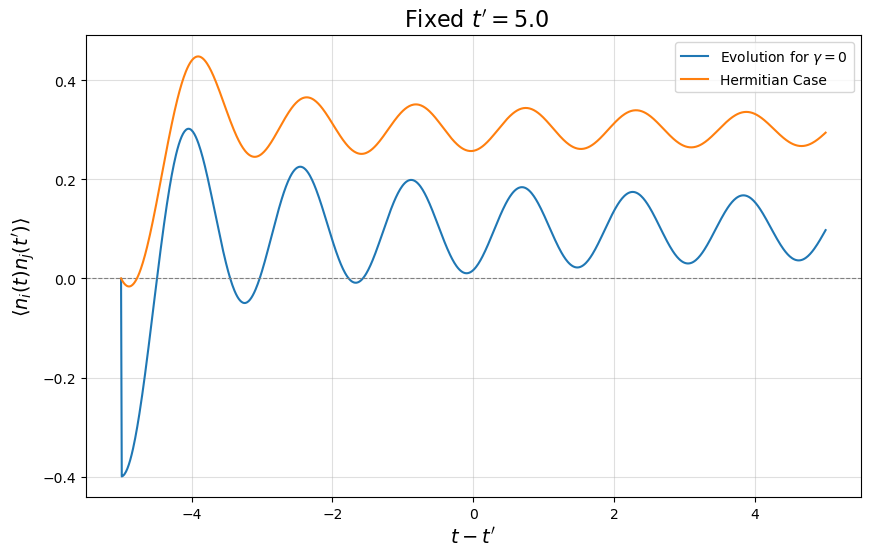

In [196]:
plt.figure(figsize=(10, 6))
plt.plot(time_differences, correlation_avgx[1,:] - correlation_avgx2[1,:] , label="Evolution for $\gamma = 0$ ")
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.xlabel(r"$t - t'$", fontsize=14)
plt.ylabel("Averaged Correlation", fontsize=14)
plt.title(f"Averaged Correlation as a function of $t - t'$ (Fixed $t' = {t_prime:.2f}$)", fontsize=16)
plt.legend()
plt.grid(alpha=0.4)



plt.plot(t_values-t_prime, correlation_values, label="Hermitian Case")

plt.xlabel(r"$t-t'$", fontsize=14)
plt.ylabel(r"$\langle n_i(t) n_j(t') \rangle $", fontsize=14)
plt.title(f" Fixed $t'={t_prime}$", fontsize=16)
plt.legend()
plt.grid(True)
plt.show()